In [7]:
# Importing Basic Libraries
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
# Load dataset
df = pd.read_csv("titanic.csv")

# Display the data (by default shows first 5 rows)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
# (Rows, Columns)
df.shape

(891, 12)

In [10]:
# Column Names
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [11]:
# Data Types of Each Column
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [12]:
# About the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [13]:
# Statistical Summary(only numeric columns)
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### Data Cleaning

In [14]:
# Count of null values per column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [15]:
# Check for duplicates
df.duplicated().sum()

np.int64(0)

In [16]:
# Count of unique classes in each categorical column

print(df['Sex'].value_counts())
print()
print(df['Pclass'].value_counts())
print()
print(df['Embarked'].value_counts())

Sex
male      577
female    314
Name: count, dtype: int64

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [17]:
# Replacing null values with median values(only numeric columns)
# Age contains extreme values( min-0 ; max-80 ) and median is not sensitive to outliers

median_val = df['Age'].median()
df['Age'] = df['Age'].fillna(median_val)

# Checking for null values again for Age column
df['Age'].isnull().sum()

np.int64(0)

In [18]:
# Replacing null values in categorical columns

mode_val = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(mode_val)

# Checking again
df['Embarked'].isnull().sum()

np.int64(0)

In [19]:
# Dropping unimportant features(Cabin)
df = df.drop('Cabin', axis=1)

df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='str')

### EDA(Exploratory Data Analysis)

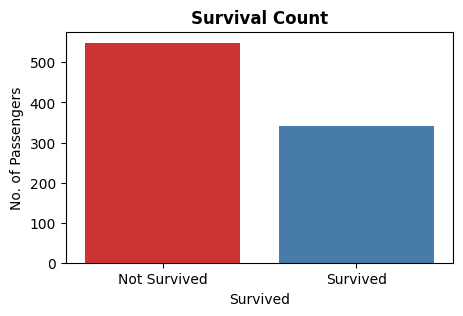

In [20]:
# Survival Distribution

plt.figure(figsize=(5,3))
sns.countplot(x ='Survived', data=df, hue='Survived',palette='Set1', legend=False)
plt.title('Survival Count', weight='bold')
plt.xlabel('Survived')
plt.xticks([0,1],['Not Survived', 'Survived'])
plt.ylabel('No. of Passengers')
plt.show()

In [21]:
# Survival Distribution by Gender(Percentage)

df.groupby('Sex')['Survived'].mean()*100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [22]:
# Survival Distribution by Passenger Class(Percentage)

df.groupby('Pclass')['Survived'].mean()*100

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64

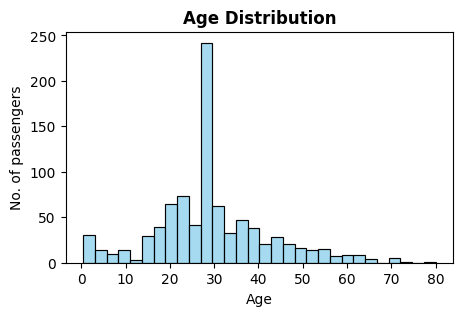

In [23]:
# Age Distribution

plt.figure(figsize=(5,3))
sns.histplot(df['Age'], bins = 30, color='skyblue')
plt.title('Age Distribution', weight='bold')
plt.xlabel('Age')
plt.ylabel('No. of passengers')
plt.show()

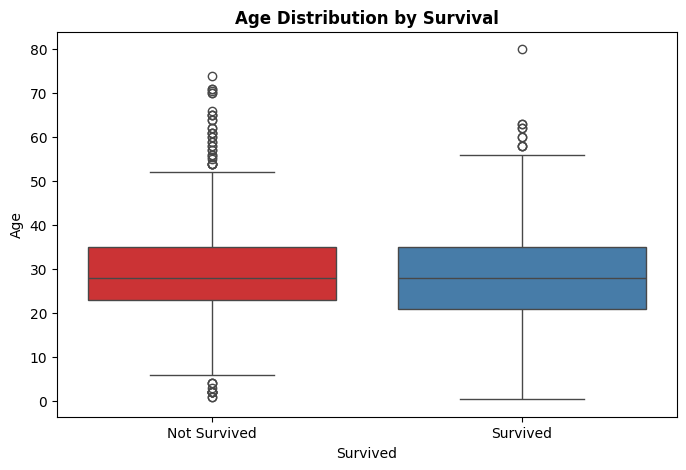

In [24]:
# Age Vs Survival Distribution

plt.figure(figsize=(8,5))
sns.boxplot(x='Survived',y='Age',data=df,hue='Survived', palette='Set1', legend=False)
plt.title('Age Distribution by Survival', weight='bold')
plt.xlabel('Survived')
plt.xticks([0,1],['Not Survived', 'Survived'])
plt.ylabel('Age')
plt.show()

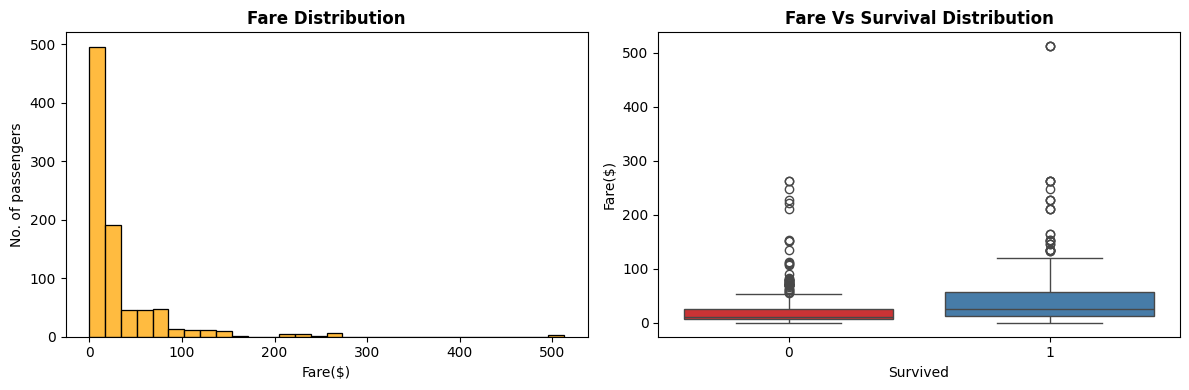

In [25]:
# Fare Distribution

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['Fare'], bins = 30, color='orange', ax=axes[0])
axes[0].set_title('Fare Distribution', weight='bold')
axes[0].set_xlabel('Fare($)')
axes[0].set_ylabel('No. of passengers')
plt.tight_layout()


# Survival by Fare Distribution

sns.boxplot(x='Survived',y='Fare',data=df,hue='Survived',palette='Set1',legend=False, ax=axes[1])
axes[1].set_title('Fare Vs Survival Distribution', weight='bold')
axes[1].set_xlabel('Survived')
axes[1].set_ylabel('Fare($)')
plt.tight_layout()
plt.show()

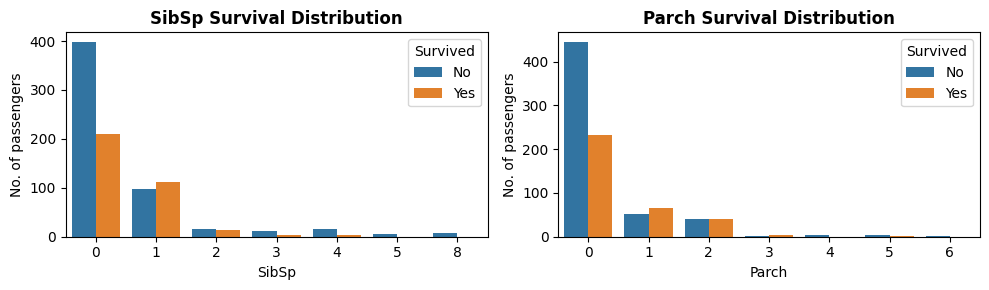

In [26]:
# SibSp- No. of siblings/spouses
# Parch- No. of parents/children

# SibSp Survival Distribution

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.countplot(x = "SibSp", hue='Survived', data=df, ax=axes[0])
axes[0].set_title('SibSp Survival Distribution', weight='bold')
axes[0].set_xlabel('SibSp')
axes[0].set_ylabel('No. of passengers')
axes[0].legend(title='Survived',labels=['No','Yes'])
plt.tight_layout()


# Parch Survival Distribution

sns.countplot(x = "Parch", hue='Survived', data=df, ax=axes[1])
axes[1].set_title('Parch Survival Distribution', weight='bold')
axes[1].set_xlabel('Parch')
axes[1].set_ylabel('No. of passengers')
axes[1].legend(title='Survived',labels=['No','Yes'])
plt.tight_layout()
plt.show()

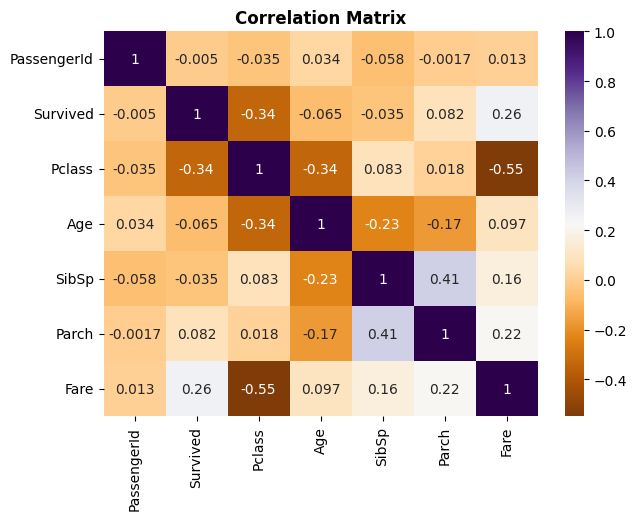

In [27]:
# Correlation Matrix

# Selecting only numeric columns
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(7,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap='PuOr')
plt.title('Correlation Matrix', weight='bold')
plt.show()

### Feature Engineering

In [28]:
# Combine SibSp and Parch to create Family

df["Family"] = df["SibSp"] + df["Parch"] + 1    # +1 to include the passenger themselves

df["isAlone"] = np.where(df["Family"] == 1, 1,0)  # 1 if alone, 0 otherwise

# df = df.drop(['SibSp', 'Parch'], axis=1)  # Dropping the original columns


In [29]:
# Dropping unimportant features(PassengerId, Name, Ticket)
df = df.drop(["PassengerId","Name","Ticket"], axis=1)

In [30]:
from sklearn.preprocessing import OneHotEncoder

# Encoding Categorical Variables
df = pd.get_dummies(df, columns=["Sex","Embarked"], drop_first=True, dtype=int)

# Check newly formed columns
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Family,isAlone,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,2,0,1,0,1
1,1,1,38.0,1,0,71.2833,2,0,0,0,0
2,1,3,26.0,0,0,7.9250,1,1,0,0,1
3,1,1,35.0,1,0,53.1000,2,0,0,0,1
4,0,3,35.0,0,0,8.0500,1,1,1,0,1


### Splitting Data and Feature Scaling

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop('Survived',axis=1)
y = df['Survived']

# Splitting data into train(80%) and test(20%)
Xtr,Xte,ytr,yte = train_test_split(X, y, test_size=0.2, random_state=46, stratify=y)

# Feature Scaling -> Change the features to fall in range of 0 to 1
scaler = StandardScaler()   # object

Xtr_scaled = scaler.fit_transform(Xtr)
Xte_scaled = scaler.transform(Xte)

### Training ML Models

Accuracy(Logistic Regression): 81.01%

Classification Report(Logistic Regression):
              precision    recall  f1-score   support

           0       0.85      0.84      0.84       110
           1       0.75      0.77      0.76        69

    accuracy                           0.81       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.81      0.81      0.81       179



Text(0.5, 1.0, 'Confusion Matrix(Logistic Regression)')

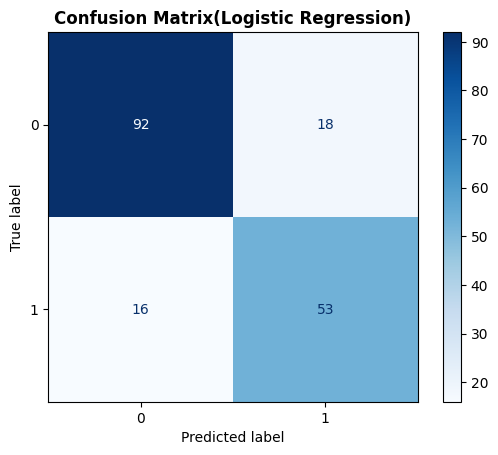

In [32]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Logistic Regression Model
model1 = LogisticRegression(random_state=42)    # random_state make sure the same random numbers are generated each time it's run
model1.fit(Xtr_scaled, ytr)

# Prediction
y_pred = model1.predict(Xte_scaled)

# Evaluation

# Accuracy
m1_acc = accuracy_score(yte,y_pred)
print(f"Accuracy(Logistic Regression): {m1_acc*100:.2f}%")
print()

# Classification Report
print(f"Classification Report(Logistic Regression):\n{classification_report(yte,y_pred)}")

# Confusion Matrix
cm = confusion_matrix(yte, y_pred, labels=model1.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model1.classes_)
disp.plot(cmap='Blues')
disp.ax_.set_title('Confusion Matrix(Logistic Regression)', weight='bold')

In [33]:
# Check for overfitting or underfitting

m1_train_acc = model1.score(Xtr_scaled, ytr)
m1_test_acc = model1.score(Xte_scaled, yte)

print(f"Train Accuracy: {m1_train_acc*100:.2f}%")
print(f"Test Accuracy: {m1_test_acc*100:.2f}%")


Train Accuracy: 80.34%
Test Accuracy: 81.01%


Accuracy(Random Forest): 82.12%

Classification Report(Random Forest):
              precision    recall  f1-score   support

           0       0.79      0.96      0.87       110
           1       0.91      0.59      0.72        69

    accuracy                           0.82       179
   macro avg       0.85      0.78      0.79       179
weighted avg       0.84      0.82      0.81       179



Text(0.5, 1.0, 'Confusion Matrix(Random Forest)')

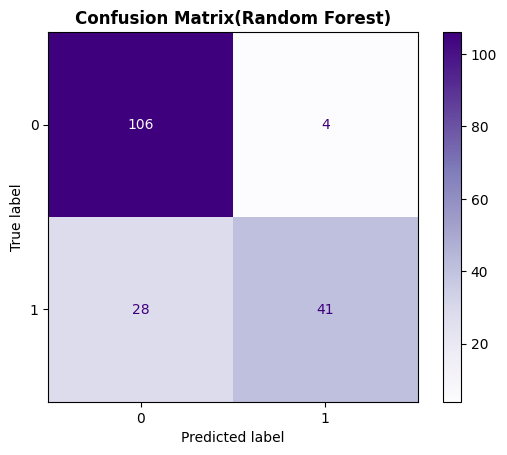

In [34]:
from sklearn.ensemble import RandomForestClassifier

# Random Forest Model
model2 = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, criterion='gini')
model2.fit(Xtr_scaled, ytr)

# prediction
y_pred = model2.predict(Xte_scaled)

# Evaluation

# Accuracy
m2_acc = accuracy_score(yte,y_pred)
print(f"Accuracy(Random Forest): {m2_acc*100:.2f}%")
print()

# Classification Report
print(f"Classification Report(Random Forest):\n{classification_report(yte,y_pred)}")

# Confusion Matrix
cm = confusion_matrix(yte, y_pred, labels=model2.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model2.classes_)
disp.plot(cmap='Purples')
disp.ax_.set_title('Confusion Matrix(Random Forest)', weight='bold')


In [35]:
# Check for overfitting or underfitting

m2_train_acc = model2.score(Xtr_scaled, ytr)
m2_test_acc = model2.score(Xte_scaled, yte)

print(f"Train Accuracy: {m2_train_acc*100:.2f}%")
print(f"Test Accuracy: {m2_test_acc*100:.2f}%")


Train Accuracy: 85.25%
Test Accuracy: 82.12%


### Model Comparison

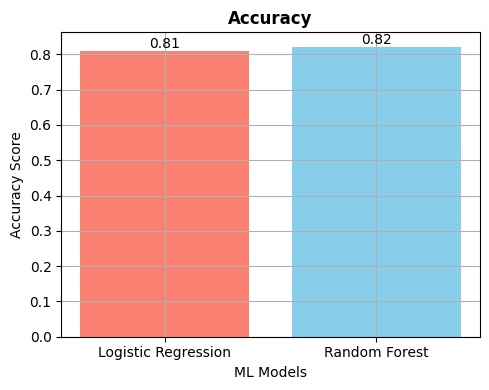

In [36]:
# Comparing Model Accuracy

plt.figure(figsize=(5,4))
bars = plt.bar(['Logistic Regression','Random Forest'],[m1_acc,m2_acc], color = ['salmon','skyblue'])
plt.title('Accuracy', weight = 'bold')
plt.xlabel("ML Models")
plt.bar_label(bars, fmt='{:.2f}')
plt.ylabel("Accuracy Score")
plt.grid(True)
plt.tight_layout()
plt.show()

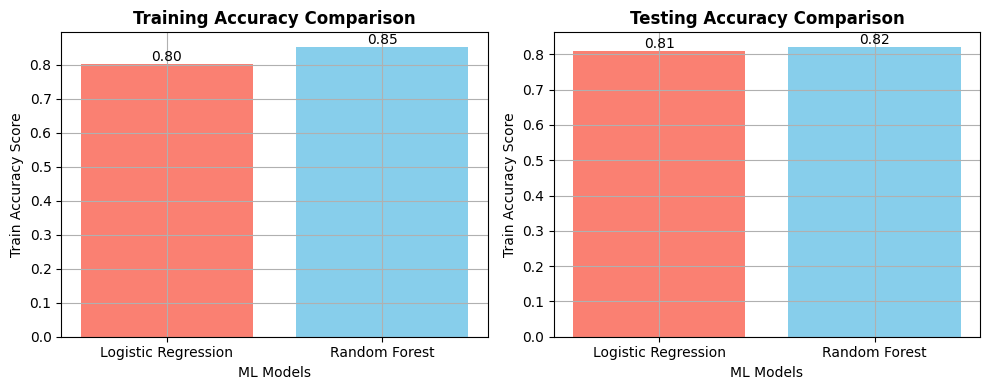

In [37]:
# Comparing Model train and test accuracy

fig, axes = plt.subplots(1,2, figsize=(10,4))
bars = axes[0].bar(['Logistic Regression','Random Forest'],[m1_train_acc, m2_train_acc], color = ['salmon','skyblue'] )
axes[0].set_title('Training Accuracy Comparison', weight = 'bold')
axes[0].set_xlabel("ML Models")
axes[0].bar_label(bars, fmt='{:.2f}')
axes[0].set_ylabel("Train Accuracy Score")
axes[0].grid(True)

bars = axes[1].bar(['Logistic Regression','Random Forest'],[m1_test_acc, m2_test_acc], color = ['salmon','skyblue'] )
axes[1].set_title('Testing Accuracy Comparison', weight = 'bold')
axes[1].set_xlabel("ML Models")
axes[1].bar_label(bars, fmt='{:.2f}')
axes[1].set_ylabel("Train Accuracy Score")
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# Saving the updated dataset
df.to_csv("updated_titanic.csv", index=False)